In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py

In [2]:
# CONTAINS SLEAP COORD + 10 ELECTRODE X 25 TIMEPOINTS PER VIDEO FRAME
# path_csv = 'data/Data_4fish_2024-10-23T15_18_28.csv'
path_csv = 'data/Data_4fish_2024-02-20T21_16_26_no_ref_per.csv'

In [3]:
df = pd.read_csv(path_csv)
print(df.columns.tolist())
print(len(df.index.tolist()))

['Frame', 'Time', 'RelativeTime', 'num_time_steps_between_eod_peaks', 'similarity_A', 'similarity_B', 'similarity_C', 'similarity_D', 'discharging_fish', 'curved_fish_length_A', 'curved_fish_length_B', 'curved_fish_length_C', 'curved_fish_length_D', 'head_score_A', 'head_score_B', 'head_score_C', 'head_score_D', 'head_x_A', 'head_x_B', 'head_x_C', 'head_x_D', 'head_y_A', 'head_y_B', 'head_y_C', 'head_y_D', 'mean_score_A', 'mean_score_B', 'mean_score_C', 'mean_score_D', 'middle_score_A', 'middle_score_B', 'middle_score_C', 'middle_score_D', 'middle_x_A', 'middle_x_B', 'middle_x_C', 'middle_x_D', 'middle_y_A', 'middle_y_B', 'middle_y_C', 'middle_y_D', 'mouth_score_A', 'mouth_score_B', 'mouth_score_C', 'mouth_score_D', 'mouth_x_A', 'mouth_x_B', 'mouth_x_C', 'mouth_x_D', 'mouth_y_A', 'mouth_y_B', 'mouth_y_C', 'mouth_y_D', 'segment_fish_length_A', 'segment_fish_length_B', 'segment_fish_length_C', 'segment_fish_length_D', 'tail_score_A', 'tail_score_B', 'tail_score_C', 'tail_score_D', 'tail_

In [4]:
df.head()

,Frame,Time,RelativeTime,num_time_steps_between_eod_peaks,similarity_A,similarity_B,similarity_C,similarity_D,discharging_fish,curved_fish_length_A,...,electrode_10_time_16,electrode_10_time_17,electrode_10_time_18,electrode_10_time_19,electrode_10_time_20,electrode_10_time_21,electrode_10_time_22,electrode_10_time_23,electrode_10_time_24,electrode_10_time_25
0,1,2024-02-20 21:16:25.543415,-0.456585,2,-0.122035,-0.644852,-0.105070,0.095289,D,13.88297,...,-0.001290,-0.000185,0.000099,0.000248,-0.000185,0.000278,0.000166,-0.000207,-0.000088,-0.000073
1,1,2024-02-20 21:16:25.545994,-0.454006,3,0.625128,0.335752,0.491262,-0.491830,A,13.88297,...,0.000107,0.000324,-0.000319,0.000062,-0.000087,0.000070,0.000346,0.000002,0.000137,0.000189
2,1,2024-02-20 21:16:25.568274,-0.431726,3,-0.305962,0.267985,0.618056,-0.512251,C,13.88297,...,0.002763,0.000217,-0.000112,-0.001157,-0.000859,-0.000874,-0.000762,-0.001456,-0.000523,-0.000903
3,1,2024-02-20 21:16:25.608113,-0.391887,2,-0.117727,-0.652779,-0.108926,0.097148,D,13.88297,...,-0.000983,0.000309,0.000235,0.000444,0.000324,0.000085,0.000519,0.000660,0.000802,0.000205
4,1,2024-02-20 21:16:25.636912,-0.363088,2,0.648553,0.272337,0.416472,-0.429102,A,13.88297,...,-0.000104,0.000434,0.000516,0.000031,0.000128,-0.000179,0.000255,-0.000343,0.000404,-0.000440


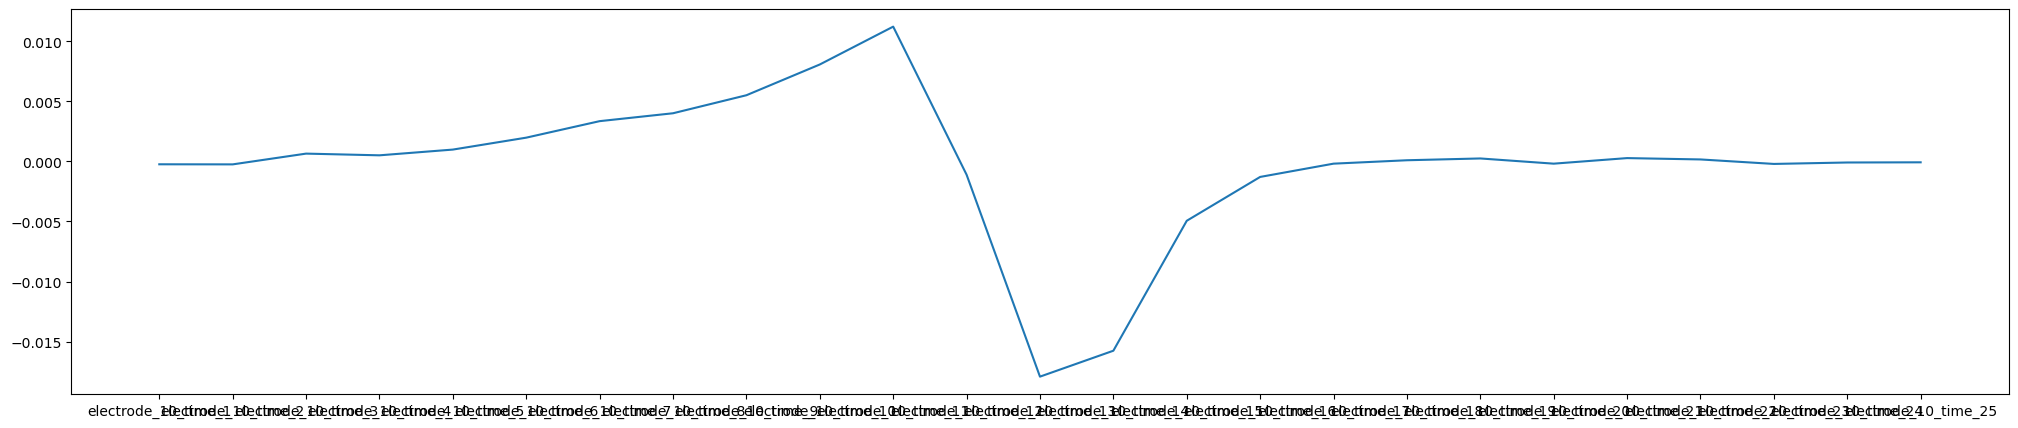

In [5]:
fig, axes = plt.subplots(figsize=(25,5))
axes.plot(df.iloc[0,-25:])

In [6]:
# EOD data ???
path_eod = "data/EODdata_2024-10-23T15_18_28.mat"  

def load_mat(path):
    try:
        from scipy.io import loadmat
        data = loadmat(path, squeeze_me=True, struct_as_record=False)
        return {k: v for k, v in data.items() if not k.startswith("__")}, "scipy"
    except NotImplementedError:
        import h5py
        return h5py.File(path, "r"), "h5py"

obj, kind = load_mat(path_eod)
print(obj.keys())


<KeysViewHDF5 ['NewRaw', 'Objtime', 'Synctime']>


In [7]:
print(obj['NewRaw'])
print(obj['Objtime'])
print(obj['Synctime'])

<HDF5 dataset "NewRaw": shape (60000000, 10), type "<f8">
<HDF5 dataset "Objtime": shape (2,), type "<u8">
<HDF5 dataset "Synctime": shape (159, 1), type "<f8">


In [8]:
print(obj['NewRaw'][10000:11000])

[[ 6.01493724e-05 -3.31303890e-04 -4.61117618e-04 ... -3.83270278e-04
  -5.08221416e-05  5.01344587e-04]
 [ 2.16780400e-04 -1.74608920e-04 -3.49188365e-04 ...  2.73557854e-04
   1.80501703e-04 -5.87149392e-05]
 [ 2.91366725e-04 -9.25284323e-05  4.94038648e-04 ... -6.97835771e-05
   2.92424155e-04 -2.75276688e-04]
 ...
 [            nan             nan             nan ...             nan
              nan             nan]
 [            nan             nan             nan ...             nan
              nan             nan]
 [            nan             nan             nan ...             nan
              nan             nan]]


In [9]:
print(obj['Synctime'][:,0])

[   6.61794   16.33888   24.0501    29.62558   35.8204    45.23372
   52.15394   60.36486   68.054     77.01782   82.40582   88.2773
   96.33882  101.4391   106.81814  115.25784  121.0221   127.40252
  133.49996  141.32432  148.45504  157.79636  165.7074   172.57928
  179.23984  184.90064  191.67204  200.4542   209.8446   215.85506
  222.27594  229.12656  237.03756  247.11946  253.8606   262.52102
  272.1621   279.93264  288.18512  297.42496  306.50606  315.60694
  320.80782  329.06734  333.95864  342.72092  349.89134  358.6918
  367.3633   374.50326  384.14352  391.16404  396.90628  404.18892
  413.13926  423.00488  429.70098  435.54036  444.54934  449.90268
  457.6645   466.08176  474.6478   481.37136  488.77034  497.43124
  505.40186  513.52338  521.77376  528.38426  537.2049   545.32632
  553.46806  560.23836  569.0997   577.14114  586.29168  596.1032
  602.94356  610.85372  619.35568  627.3365   632.62302  639.71744
  646.09754  655.50832  661.73842  667.26862  673.28944  680.4301

In [10]:
# EOD data ???
path_video = "data/video2024-10-23T15_18_28.mat"  

def load_mat(path):
    try:
        from scipy.io import loadmat
        data = loadmat(path, squeeze_me=True, struct_as_record=False)
        return {k: v for k, v in data.items() if not k.startswith("__")}, "scipy"
    except NotImplementedError:
        import h5py
        return h5py.File(path, "r"), "h5py"

obj, kind = load_mat(path_video)
print(obj.keys())

<KeysViewHDF5 ['Synctime_video']>


In [11]:
print(obj['Synctime_video'][:,0])

[   5.92   15.62   23.3    28.82   35.06   44.6    51.56   59.78   67.22
   76.34   81.78   87.62   95.78  100.82  106.1   114.5   120.46  126.74
  132.7   140.64  147.8   157.22  165.12  172.    178.58  184.34  191.06
  199.82  209.34  215.24  221.78  228.64  236.46  246.5   253.22  262.06
  271.6   279.46  287.72  296.9   306.02  315.14  320.3   328.34  333.54
  342.22  349.46  358.26  366.74  373.94  383.74  390.74  396.3   403.66
  412.62  422.38  429.24  435.14  443.92  449.56  457.22  465.56  474.26
  480.78  488.44  497.08  504.98  513.12  521.3   528.02  536.9   544.96
  553.08  559.94  568.82  576.74  585.86  595.7   602.66  610.58  618.98
  627.06  632.18  639.38  645.86  655.22  661.46  667.04  672.96  680.12
  686.94  695.78  704.86  712.46  719.02  724.82  730.28  738.88  744.5
  750.74  756.6   765.62  771.34  778.1   786.66  793.22  802.1   810.98
  819.56  825.5   831.14  838.1   847.06  852.98  860.1   869.78  877.94
  884.42  889.64  897.78  905.26  912.74  919.94  92

## IDI (inter-discharge interval) distribution per fish

In [17]:
fish_colors = {'A': '#2a78d6', 'B': '#e34948', 'C': '#008300', 'D': '#4a3aa7'}

idi_ms_by_fish = {}
for fish in fish_colors:
    t = df.loc[df['discharging_fish'] == fish, 'RelativeTime'].sort_values().values
    idi_ms_by_fish[fish] = np.diff(t) * 1000  # seconds -> ms

    print((idi_ms_by_fish[fish] < 8).mean()*100)

for fish, idi in idi_ms_by_fish.items():
    print(f"Fish {fish}: n_discharges={len(idi)+1}, median IDI={np.median(idi):.1f} ms")

4.191416939197758
3.1050407782254106
5.668515095502157
4.400173235166739
Fish A: n_discharges=14984, median IDI=40.8 ms
Fish B: n_discharges=10178, median IDI=56.6 ms
Fish C: n_discharges=17854, median IDI=42.6 ms
Fish D: n_discharges=11546, median IDI=49.8 ms


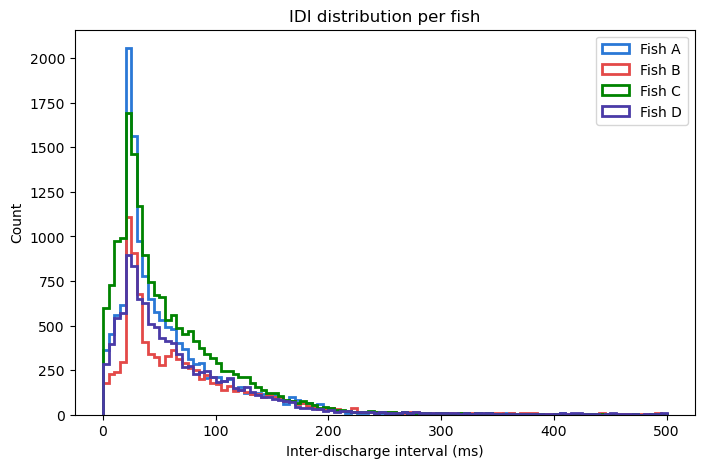

In [13]:
fish_linestyles = {'A': '-', 'B': '-', 'C': '-', 'D': '-'}

fig, ax = plt.subplots(figsize=(8, 5))
for fish, idi in idi_ms_by_fish.items():
    ax.hist(idi, bins=100, range=(0, 500), histtype='step', linewidth=2,
             color=fish_colors[fish], linestyle=fish_linestyles[fish], label=f'Fish {fish}')
ax.set_xlabel('Inter-discharge interval (ms)')
ax.set_ylabel('Count')
ax.set_title('IDI distribution per fish')
ax.legend()
plt.show()

## EOD cessations (pauses in discharging)

A "cessation" is defined relative to each fish's own baseline firing rate rather than a fixed IDI cutoff, since fish differ (median IDI ranges ~41-57ms above). An IDI is flagged as a cessation when it is at least **10x that fish's median IDI** — an order-of-magnitude, sudden drop in discharge rate that a fixed threshold (e.g. always >300ms) would over- or under-count depending on the fish. Cessations are then split at **1s** into short vs long, per the requested threshold.

In [ ]:
cessation_factor = 10       # IDI >= factor * fish's own median IDI counts as a cessation
short_long_boundary_s = 1.0  # split requested by user

cessations_by_fish = {}
for fish in fish_colors:
    idi_s = idi_ms_by_fish[fish] / 1000  # back to seconds
    thresh_s = cessation_factor * np.median(idi_s)
    cessations_by_fish[fish] = idi_s[idi_s >= thresh_s]
    print(f"Fish {fish}: cessation threshold={thresh_s*1000:.0f} ms", end='  ')

    cess = cessations_by_fish[fish]
    n_short = (cess < short_long_boundary_s).sum()
    n_long = (cess >= short_long_boundary_s).sum()
    print(f"| n_cessations={len(cess)} (short<1s: {n_short}, long>=1s: {n_long})")

In [ ]:
bins = np.logspace(np.log10(0.1), np.log10(30), 40)  # log-spaced: durations span ~0.1-25s

fig, ax = plt.subplots(figsize=(8, 5))
for fish, cess in cessations_by_fish.items():
    ax.hist(cess, bins=bins, histtype='step', linewidth=2, color=fish_colors[fish], label=f'Fish {fish}')
ax.axvline(short_long_boundary_s, color='gray', linestyle=':', linewidth=1, label='short/long boundary (1s)')
ax.set_xscale('log')
ax.set_xlabel('Cessation duration (s)')
ax.set_ylabel('Count')
ax.set_title('Distribution of EOD cessation durations per fish')
ax.legend()
plt.show()

## Behavioral kinematics from SLEAP coordinates (speed, rotational speed, acceleration)

Position columns repeat across every EOD-event row that shares a video `Frame`, so we first dedupe to one row per frame. Centroid = `middle` keypoint; heading = angle of the tail->head vector. `Frame` intervals are irregular here (this file only contains frames with >=1 EOD event, median ~26ms / ~38fps but with gaps up to ~0.5s), so all derivatives use the real per-frame time delta rather than an assumed frame rate. Units are pixels (no px->cm calibration found in this file). Estimates at very small dt (<5ms) are dropped since pixel jitter divided by a tiny dt blows up into spurious spikes.

In [ ]:
kp_cols = [f'{p}_{c}_{fish}' for p in ('head', 'middle', 'tail') for c in ('x', 'y') for fish in fish_colors]
frame_df = df[['Frame', 'Time'] + kp_cols].drop_duplicates(subset='Frame').sort_values('Frame').reset_index(drop=True)

def compute_kinematics(fr, fish, dt_min_s=0.005):
    t = pd.to_datetime(fr['Time']).values.astype('datetime64[ns]').astype(np.int64) / 1e9
    dt = np.diff(t)  # s, real per-frame delta (irregular)

    x, y = fr[f'middle_x_{fish}'].values, fr[f'middle_y_{fish}'].values
    speed = np.hypot(np.diff(x), np.diff(y)) / dt  # px/s, centroid = middle keypoint
    speed[dt < dt_min_s] = np.nan

    hx, hy = fr[f'head_x_{fish}'].values, fr[f'head_y_{fish}'].values
    tx, ty = fr[f'tail_x_{fish}'].values, fr[f'tail_y_{fish}'].values
    heading = np.arctan2(hy - ty, hx - tx)  # body-axis angle, tail -> head
    dtheta = np.arctan2(np.sin(np.diff(heading)), np.cos(np.diff(heading)))  # wrapped to [-pi, pi]
    rot_speed = dtheta / dt  # rad/s
    rot_speed[dt < dt_min_s] = np.nan

    accel = np.r_[np.nan, np.diff(speed) / dt[1:]]  # px/s^2, change in speed, padded to align with Frame[1:]

    return pd.DataFrame({'Frame': fr['Frame'].values[1:], 'speed': speed, 'rot_speed': rot_speed, 'accel': accel})

kinematics_by_fish = {fish: compute_kinematics(frame_df, fish) for fish in fish_colors}
for fish, k in kinematics_by_fish.items():
    print(f"Fish {fish}: median speed={k['speed'].median():.1f} px/s, "
          f"median |rot speed|={k['rot_speed'].abs().median():.2f} rad/s, "
          f"median |accel|={k['accel'].abs().median():.1f} px/s^2")

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
specs = [('speed', 'Speed (px/s)'), ('rot_speed', 'Rotational speed (rad/s)'), ('accel', 'Acceleration (px/s^2)')]
for ax, (col, xlabel) in zip(axes, specs):
    pooled = pd.concat([k[col] for k in kinematics_by_fish.values()]).dropna()
    rng = np.nanpercentile(pooled, [1, 99])  # adaptive range: drop the extreme 1% tails per feature
    for fish, k in kinematics_by_fish.items():
        ax.hist(k[col].dropna(), bins=80, range=rng, histtype='step', linewidth=2,
                 color=fish_colors[fish], label=f'Fish {fish}')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Count')
axes[0].legend()
fig.suptitle('Behavioral kinematics distributions per fish (1st-99th percentile range)')
plt.tight_layout()
plt.show()

## Pairwise and single-body features (aggression-relevant)

Distance and relative orientation between fish are the core features in weakly-electric-fish agonistic-behavior research — e.g. "head-to-head" vs. "head-to-tail" encounters, which are classic triggers for jamming-avoidance and dominance displays. Note: the raw file already has `distance_A-B`-style columns, but they're **asymmetric** (`distance_A-B != distance_B-A`) and in a different, already-calibrated physical unit — they look like a snout/head-referenced social distance, not a plain centroid-to-centroid one. Rather than guess at their exact definition, we compute a clean, symmetric, well-understood alternative below:

- **Calibration**: `curved_fish_length` is already in physical units (its pixel/value ratio is ~13.5, consistent across fish and frames), so we derive a px-per-unit scale factor and report distances in body-length units instead of raw pixels.
- **Pairwise distance** (6 unordered pairs): centroid-to-centroid, in body-length units — proximity is the first-order proxy for a social interaction.
- **Pairwise heading alignment** (6 unordered pairs): angular difference between two fish's body-axis headings, 0deg=swimming parallel, 180deg=facing opposite directions.
- **Egocentric bearing** (12 ordered pairs, printed as a table rather than 12 overlapping histograms): where fish j sits relative to fish i's own heading — near 0deg means i is oriented toward/following j, which is more diagnostic of chasing/approach than symmetric distance alone.
- **Body bend angle** (per fish): angle between the head->middle and middle->tail vectors; large deviations from a straight body mark sharp turns (C-starts), often seen in strikes or evasive maneuvers.
- **Freeze / burst fraction** (per fish): fraction of time each fish's speed sits in the bottom/top 10% pooled across all fish — sustained low speed (freezing) is a common submission/subordinate signal, sustained high speed marks chase/attack bursts.

In [ ]:
from itertools import combinations, permutations

len_cols = [f'curved_fish_length_{fish}' for fish in fish_colors]
frame_df = frame_df.merge(df[['Frame'] + len_cols].drop_duplicates(subset='Frame'), on='Frame', how='left')

px_per_unit = np.nanmedian(np.concatenate([
    (np.hypot(frame_df[f'head_x_{fish}'] - frame_df[f'tail_x_{fish}'],
              frame_df[f'head_y_{fish}'] - frame_df[f'tail_y_{fish}']) / frame_df[f'curved_fish_length_{fish}']).values
    for fish in fish_colors
]))
print(f"Calibration: {px_per_unit:.2f} px per curved_fish_length unit")

headings = {fish: np.arctan2(frame_df[f'head_y_{fish}'] - frame_df[f'tail_y_{fish}'],
                              frame_df[f'head_x_{fish}'] - frame_df[f'tail_x_{fish}']).values
            for fish in fish_colors}

pair_colors = {('A', 'B'): '#2a78d6', ('A', 'C'): '#008300', ('A', 'D'): '#4a3aa7',
               ('B', 'C'): '#e34948', ('B', 'D'): '#e87ba4', ('C', 'D'): '#eb6834'}

pair_distance, pair_heading_align = {}, {}
for i, j in pair_colors:
    dx = frame_df[f'middle_x_{i}'] - frame_df[f'middle_x_{j}']
    dy = frame_df[f'middle_y_{i}'] - frame_df[f'middle_y_{j}']
    pair_distance[(i, j)] = np.hypot(dx, dy) / px_per_unit  # body-length units

    dh = headings[i] - headings[j]
    pair_heading_align[(i, j)] = np.degrees(np.abs(np.arctan2(np.sin(dh), np.cos(dh))))  # 0=aligned, 180=opposed

    print(f"{i}-{j}: median distance={np.median(pair_distance[(i,j)]):.1f} body-lengths, "
          f"median heading diff={np.median(pair_heading_align[(i,j)]):.1f} deg")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for (i, j), color in pair_colors.items():
    axes[0].hist(pair_distance[(i, j)], bins=80, histtype='step', linewidth=2, color=color, label=f'{i}-{j}')
    axes[1].hist(pair_heading_align[(i, j)], bins=60, range=(0, 180), histtype='step', linewidth=2, color=color, label=f'{i}-{j}')
axes[0].set_xlabel('Inter-fish distance (body-length units)')
axes[1].set_xlabel('Heading difference (deg, 0=aligned, 180=facing opposite)')
for ax in axes:
    ax.set_ylabel('Count')
    ax.legend(fontsize=8)
fig.suptitle('Pairwise distance and relative heading, per fish pair')
plt.tight_layout()
plt.show()

In [ ]:
bearing_rows = []
for i, j in permutations(fish_colors, 2):
    dx = frame_df[f'middle_x_{j}'] - frame_df[f'middle_x_{i}']
    dy = frame_df[f'middle_y_{j}'] - frame_df[f'middle_y_{i}']
    absolute_bearing = np.arctan2(dy, dx)
    bearing = np.degrees(np.arctan2(np.sin(absolute_bearing - headings[i]), np.cos(absolute_bearing - headings[i])))
    bearing_rows.append({'from': i, 'to': j, 'median_bearing_deg': np.median(bearing),
                          'frac_j_ahead_of_i': (np.abs(bearing) < 45).mean()})

bearing_df = pd.DataFrame(bearing_rows).sort_values('frac_j_ahead_of_i', ascending=False).reset_index(drop=True)
bearing_df

In [ ]:
bend_by_fish = {}
for fish in fish_colors:
    v_head = np.arctan2(frame_df[f'head_y_{fish}'] - frame_df[f'middle_y_{fish}'], frame_df[f'head_x_{fish}'] - frame_df[f'middle_x_{fish}'])
    v_tail = np.arctan2(frame_df[f'middle_y_{fish}'] - frame_df[f'tail_y_{fish}'], frame_df[f'middle_x_{fish}'] - frame_df[f'tail_x_{fish}'])
    dv = v_head - v_tail
    bend_by_fish[fish] = np.degrees(np.abs(np.arctan2(np.sin(dv), np.cos(dv))))  # 0=straight body

pooled_speed = pd.concat([k['speed'] for k in kinematics_by_fish.values()]).dropna()
freeze_thresh, burst_thresh = np.percentile(pooled_speed, [10, 90])  # adaptive, from the pooled speed distribution

for fish in fish_colors:
    speed = kinematics_by_fish[fish]['speed']
    print(f"Fish {fish}: median bend={np.median(bend_by_fish[fish]):.1f} deg, "
          f"freeze frac (speed<{freeze_thresh:.0f}px/s)={(speed < freeze_thresh).mean():.2f}, "
          f"burst frac (speed>{burst_thresh:.0f}px/s)={(speed > burst_thresh).mean():.2f}")

fig, ax = plt.subplots(figsize=(8, 5))
for fish in fish_colors:
    ax.hist(bend_by_fish[fish], bins=80, range=(0, 90), histtype='step', linewidth=2, color=fish_colors[fish], label=f'Fish {fish}')
ax.set_xlabel('Body bend angle (deg, 0=straight)')
ax.set_ylabel('Count')
ax.set_title('Body bend-angle distribution per fish')
ax.legend()
plt.show()